In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import BaggingClassifier, AdaBoostClassifier, RandomForestClassifier, VotingClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

In [24]:
df = pd.read_excel("/content/E Commerce Dataset.xlsx", sheet_name="E Comm")
df = df.drop(columns="CustomerID")
print("Shape:", df.shape)
print("Duplicate rows:", df.duplicated().sum())
df.head()

Shape: (5630, 19)
Duplicate rows: 556


,Churn,Tenure,PreferredLoginDevice,CityTier,WarehouseToHome,PreferredPaymentMode,Gender,HourSpendOnApp,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,CouponUsed,OrderCount,DaySinceLastOrder,CashbackAmount
0,1,4.0,Mobile Phone,3,6.0,Debit Card,Female,3.0,3,Laptop & Accessory,2,Single,9,1,11.0,1.0,1.0,5.0,159.93
1,1,NaN,Phone,1,8.0,UPI,Male,3.0,4,Mobile,3,Single,7,1,15.0,0.0,1.0,0.0,120.90
2,1,NaN,Phone,1,30.0,Debit Card,Male,2.0,4,Mobile,3,Single,6,1,14.0,0.0,1.0,3.0,120.28
3,1,0.0,Phone,3,15.0,Debit Card,Male,2.0,4,Laptop & Accessory,5,Single,8,0,23.0,0.0,1.0,3.0,134.07
4,1,0.0,Phone,1,12.0,CC,Male,NaN,3,Mobile,5,Single,3,0,11.0,1.0,1.0,3.0,129.60


In [25]:
df = df.drop_duplicates().reset_index(drop=True)
print( df.shape)
print()
print(df.isna().sum()[df.isna().sum() > 0])

(5074, 19)

Tenure                         231
WarehouseToHome                221
HourSpendOnApp                 230
OrderAmountHikeFromlastYear    252
CouponUsed                     210
OrderCount                     243
DaySinceLastOrder              288
dtype: int64


In [26]:
num_features = df.drop(columns="Churn").select_dtypes(include="number").columns

def count_outliers(s):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

outliers = df[num_features].apply(count_outliers).sort_values(ascending=False)
print(outliers)

OrderCount                     673
CouponUsed                     610
CashbackAmount                 382
NumberOfDeviceRegistered       363
DaySinceLastOrder               57
OrderAmountHikeFromlastYear     29
HourSpendOnApp                   6
Tenure                           4
NumberOfAddress                  4
WarehouseToHome                  2
CityTier                         0
Complain                         0
SatisfactionScore                0
dtype: int64


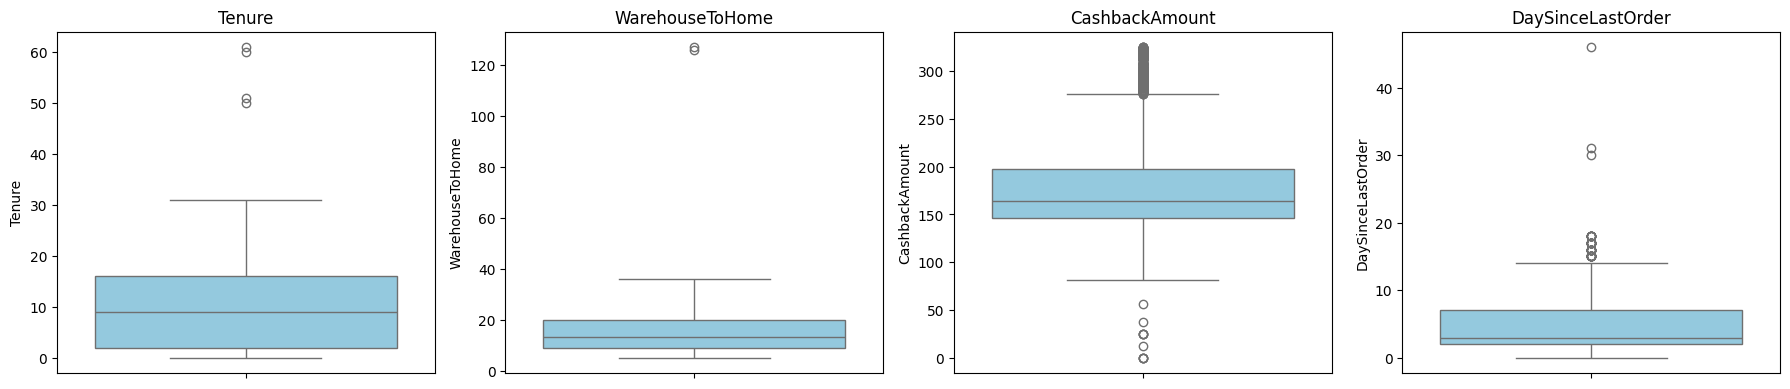

In [27]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
key_nums = ["Tenure", "WarehouseToHome", "CashbackAmount", "DaySinceLastOrder"]
for ax, col in zip(axes, key_nums):
    sns.boxplot(y=df[col], ax=ax, color="skyblue")
    ax.set_title(col)
plt.tight_layout()
plt.show()

/tmp/ipykernel_1248/3840086961.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x="Churn", data=df, palette="Set2")


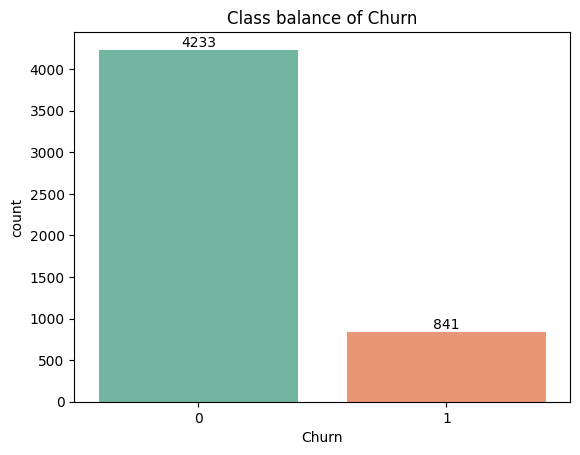

Churn
0    0.834
1    0.166
Name: proportion, dtype: float64


In [28]:
ax = sns.countplot(x="Churn", data=df, palette="Set2")
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
plt.title("Class balance of Churn")
plt.show()
print(df["Churn"].value_counts(normalize=True).round(3))

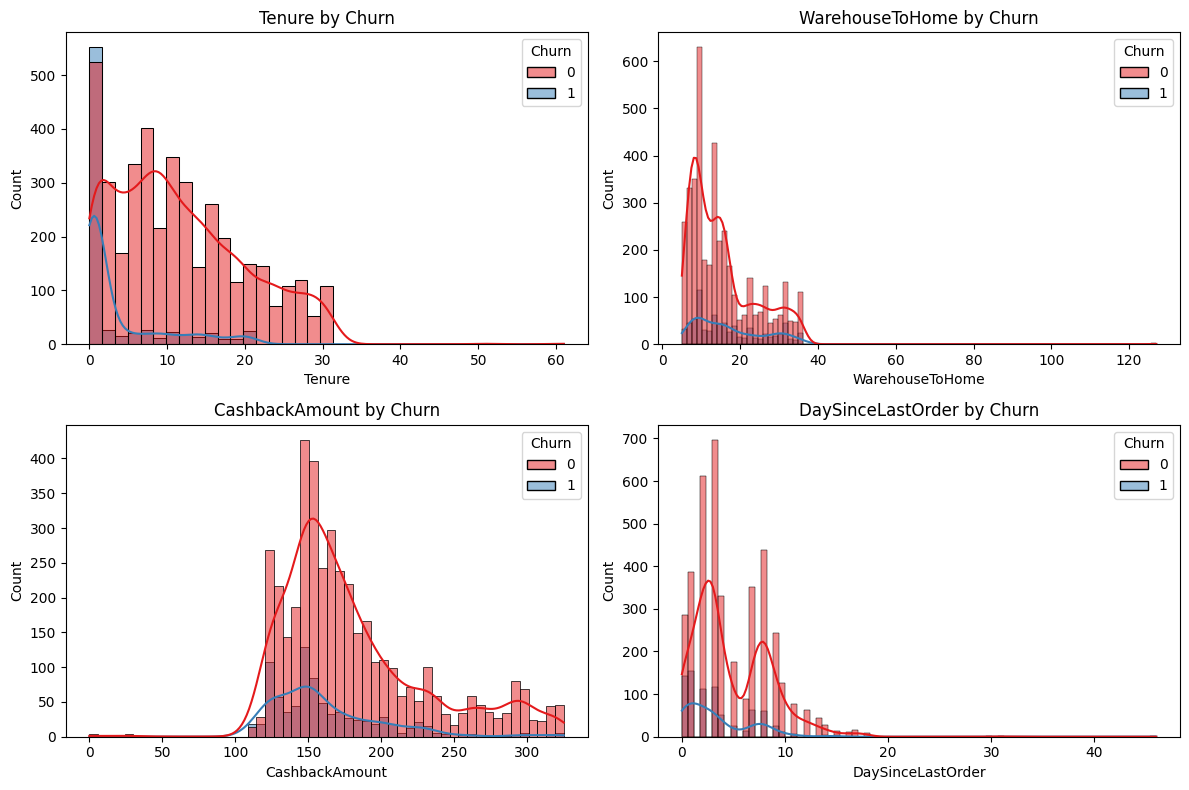

In [29]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.ravel(), key_nums):
    sns.histplot(data=df, x=col, hue="Churn", kde=True, ax=ax, palette="Set1")
    ax.set_title(f"{col} by Churn")
plt.tight_layout()
plt.show()

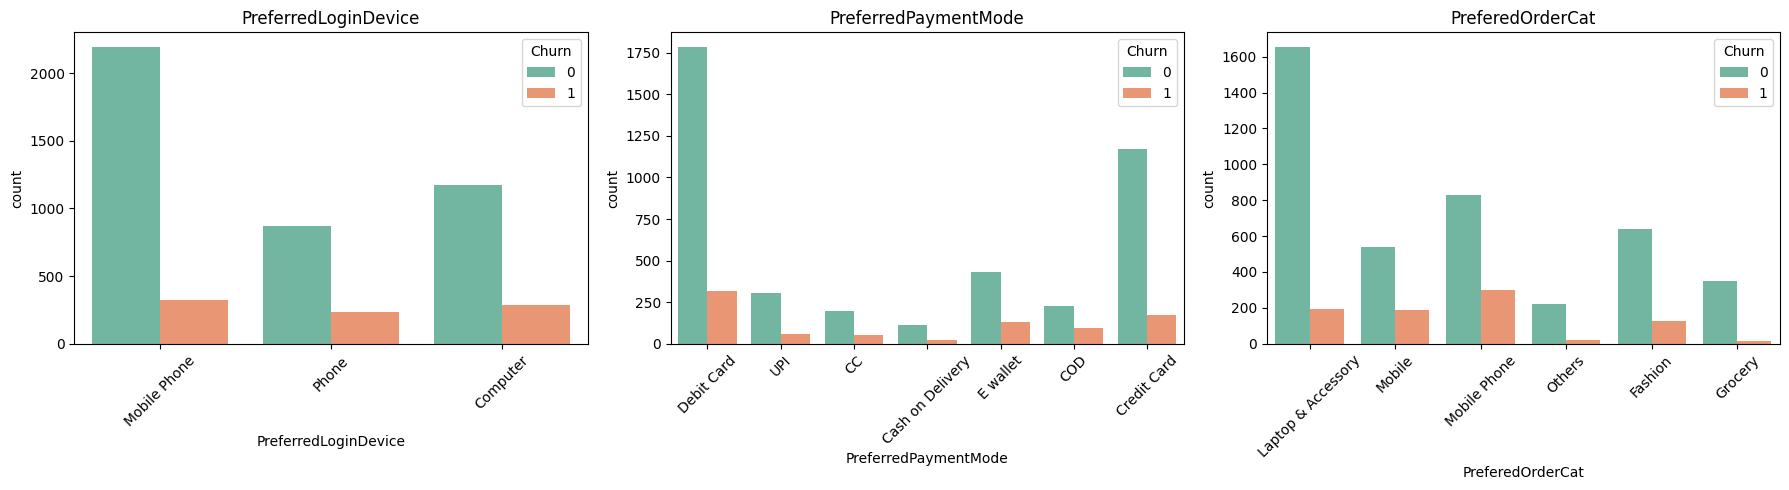

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, col in zip(axes, ["PreferredLoginDevice", "PreferredPaymentMode", "PreferedOrderCat"]):
    sns.countplot(data=df, x=col, hue="Churn", ax=ax, palette="Set2")
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

In [31]:
X = df.drop(columns="Churn")
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

print( X_train.shape, X_test.shape)
print( round(y_train.mean(), 3), round(y_test.mean(), 3))

(4059, 18) (1015, 18)
0.166 0.166


In [32]:
numirecal_cols = X_train.select_dtypes(include="number").columns.tolist()
categorical_cols = X_train.select_dtypes(exclude="number").columns.tolist()

print(numirecal_cols)
print()
print(categorical_cols)

['Tenure', 'CityTier', 'WarehouseToHome', 'HourSpendOnApp', 'NumberOfDeviceRegistered', 'SatisfactionScore', 'NumberOfAddress', 'Complain', 'OrderAmountHikeFromlastYear', 'CouponUsed', 'OrderCount', 'DaySinceLastOrder', 'CashbackAmount']

['PreferredLoginDevice', 'PreferredPaymentMode', 'Gender', 'PreferedOrderCat', 'MaritalStatus']


In [33]:
median_imputer = SimpleImputer(strategy="median")
median_imputer.fit(X_train[numirecal_cols])

learned = pd.Series(median_imputer.statistics_, index=numirecal_cols)
print(learned)
print()
print(hasattr(median_imputer, "median_"))

Tenure                           9.00
CityTier                         1.00
WarehouseToHome                 13.00
HourSpendOnApp                   3.00
NumberOfDeviceRegistered         4.00
SatisfactionScore                3.00
NumberOfAddress                  3.00
Complain                         0.00
OrderAmountHikeFromlastYear     15.00
CouponUsed                       1.00
OrderCount                       2.00
DaySinceLastOrder                3.00
CashbackAmount                 163.49
dtype: float64

False


In [78]:
cat_imputed = SimpleImputer(strategy="most_frequent").fit_transform(X_train[numirecal_cols])

ohe = OneHotEncoder(handle_unknown="ignore")
ohe_output = ohe.fit_transform(cat_imputed)
print(type(ohe_output))
print(ohe_output.shape)
print(ohe_output.nnz, ohe_output.shape[0] * ohe_output.shape[1])

<class 'scipy.sparse._csr.csr_matrix'>
(4059, 2546)
52767 10334214


In [35]:
num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", MinMaxScaler()),
])
cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])
preprocessor = ColumnTransformer([
    ("num", num_pipeline, numirecal_cols),
    ("cat", cat_pipeline, categorical_cols),
])
master_pipeline = Pipeline([
    ("prep", preprocessor),
    ("clf", DecisionTreeClassifier(max_depth=5, random_state=42)),
])
master_pipeline.fit(X_train, y_train)
print( round(master_pipeline.score(X_test, y_test), 4))

0.8739


In [36]:
X_train_p = preprocessor.fit_transform(X_train)
X_test_p = preprocessor.transform(X_test)
print(X_train_p.shape, X_test_p.shape)

(4059, 34) (1015, 34)


In [37]:
def evaluate(name, y_true, y_pred):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred),
    }

In [38]:
stump = DecisionTreeClassifier(max_depth=1, random_state=42).fit(X_train_p, y_train)
deep_tree = DecisionTreeClassifier(random_state=42).fit(X_train_p, y_train)

print([stump.score(X_train_p, y_train), deep_tree.score(X_train_p, y_train)])
print([stump.score(X_test_p, y_test), deep_tree.score(X_test_p, y_test)])

[0.8435575264843558, 1.0]
[0.8246305418719212, 0.9586206896551724]


In [39]:
depths = [1, 2, 3, 5, 8, 12, 20]
rows = []
for d in depths:
    tree = DecisionTreeClassifier(max_depth=d, random_state=42).fit(X_train_p, y_train)
    rows.append((d, tree.score(X_train_p, y_train), tree.score(X_test_p, y_test)))


In [79]:
fractions = [0.1, 0.25, 0.5, 0.75, 1.0]
for f in fractions:
    n = int(len(X_train_p) * f)
    m = DecisionTreeClassifier(max_depth=1, random_state=42)
    m.fit(X_train_p[:n], y_train.iloc[:n])
    train_acc = m.score(X_train_p[:n], y_train.iloc[:n])
    test_acc = m.score(X_test_p, y_test)
    print(f"\ntraining data: {f*100:.0f}%")
    print(f"training rows: {n}")
    print(f"stump train accuracy: {train_acc:.4f}")
    print(f"stump test accuracy: {test_acc:.4f}")
complex_model = DecisionTreeClassifier(max_depth=8, random_state=42).fit(
    X_train_p, y_train
)
print("Train Accuracy:", round(complex_model.score(X_train_p, y_train), 4))
print("Test Accuracy:", round(complex_model.score(X_test_p, y_test), 4))


training data: 10%
training rows: 405
stump train accuracy: 0.8346
stump test accuracy: 0.8246

training data: 25%
training rows: 1014
stump train accuracy: 0.8363
stump test accuracy: 0.8246

training data: 50%
training rows: 2029
stump train accuracy: 0.8349
stump test accuracy: 0.8345

training data: 75%
training rows: 3044
stump train accuracy: 0.8380
stump test accuracy: 0.8246

training data: 100%
training rows: 4059
stump train accuracy: 0.8436
stump test accuracy: 0.8246
Train Accuracy: 0.9411
Test Accuracy: 0.9133


In [80]:
configs = {
    "L2 (Ridge)": LogisticRegression(penalty="l2", solver="saga", max_iter=2000, random_state=42),
    "L1 (Lasso)": LogisticRegression(penalty="l1", solver="saga", max_iter=2000, random_state=42),
    "elastic net": LogisticRegression(penalty="elasticnet", l1_ratio=0.5, solver="saga", max_iter=2000, random_state=42),
}
for name, model in configs.items():
    model.fit(X_train_p, y_train)
    row = evaluate(name, y_test, model.predict(X_test_p))
    print(f"model: {name}")
    for metric, value in row.items():
        if metric != "Model":
            print(f"{metric}: {value:.4f}" if isinstance(value, (int, float)) else f"{metric}: {value}")
    print(f"train Accuracy: {model.score(X_train_p, y_train):.4f}")
    print(f"zero Coefficients: {int((model.coef_ == 0).sum())}")
    print(f"total Coefficients: {model.coef_.size}")


model: L2 (Ridge)
Accuracy: 0.8818
Precision: 0.7500
Recall: 0.4286
F1: 0.5455
train Accuracy: 0.8923
zero Coefficients: 0
total Coefficients: 34
model: L1 (Lasso)
Accuracy: 0.8837
Precision: 0.7232
Recall: 0.4821
F1: 0.5786
train Accuracy: 0.8950
zero Coefficients: 5
total Coefficients: 34
model: elastic net
Accuracy: 0.8818
Precision: 0.7353
Recall: 0.4464
F1: 0.5556
train Accuracy: 0.8946
zero Coefficients: 4
total Coefficients: 34


In [69]:
bagging = BaggingClassifier(
    estimator=DecisionTreeClassifier(random_state=42),
    n_estimators=100,
    bootstrap=True,
    oob_score=True,
    n_jobs=-1,
    random_state=42,
).fit(X_train_p, y_train)

pasting = BaggingClassifier(
    estimator=DecisionTreeClassifier(random_state=42),
    n_estimators=100,
    max_samples=0.8,
    bootstrap=False,
    n_jobs=-1,
    random_state=42,
).fit(X_train_p, y_train)

print(round(bagging.oob_score_, 4))
print(round(bagging.score(X_test_p, y_test), 4))
print(round(pasting.score(X_test_p, y_test), 4))

0.9576
0.9665
0.9695


In [46]:
ada = AdaBoostClassifier(n_estimators=200, learning_rate=0.5, random_state=42).fit(X_train_p, y_train)
ada_result = evaluate("AdaBoost", y_test, ada.predict(X_test_p))
print(ada_result)

{'Model': 'AdaBoost', 'Accuracy': 0.8807881773399014, 'Precision': 0.7155963302752294, 'Recall': 0.4642857142857143, 'F1': 0.5631768953068592}


In [47]:
log_reg = LogisticRegression(max_iter=2000, random_state=42)
forest = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
svc = SVC(probability=True, random_state=42)
estimators = [("lr", log_reg), ("rf", forest), ("svc", svc)]
hard_vote = VotingClassifier(estimators, voting="hard").fit(X_train_p, y_train)
soft_vote = VotingClassifier(estimators, voting="soft").fit(X_train_p, y_train)
print(hard_vote.score(X_test_p, y_test))
print(soft_vote.score(X_test_p, y_test))


0.9024630541871921
0.9054187192118227


In [81]:
all_models = {
    "Stump": stump,
    "Full tree": deep_tree,
    "Bagging": bagging,
    "Pasting": pasting,
    "AdaBoost": ada,
    "Voting (hard)": hard_vote,
    "Voting (soft)": soft_vote,
}
for name, model in configs.items():
    all_models[f"LogReg {name}"] = model
results = []

for name, model in all_models.items():
    row = evaluate(name, y_test, model.predict(X_test_p))
    results.append(row)
results = sorted(results, key=lambda x: x["F1"], reverse=True)

for rank, row in enumerate(results, start=1):
    print(f"Rank {rank}: {row['Model']}")
    for metric, value in row.items():
        if metric != "Model":
            print(f"{metric}: {value:.4f}")
    print("\n")


Rank 1: Pasting
Accuracy: 0.9695
Precision: 0.9363
Recall: 0.8750
F1: 0.9046


Rank 2: Bagging
Accuracy: 0.9665
Precision: 0.9241
Recall: 0.8690
F1: 0.8957


Rank 3: Full tree
Accuracy: 0.9586
Precision: 0.8621
Recall: 0.8929
F1: 0.8772


Rank 4: Voting (soft)
Accuracy: 0.9054
Precision: 0.8673
Recall: 0.5060
F1: 0.6391


Rank 5: Voting (hard)
Accuracy: 0.9025
Precision: 0.9157
Recall: 0.4524
F1: 0.6056


Rank 6: LogReg L1 (Lasso)
Accuracy: 0.8837
Precision: 0.7232
Recall: 0.4821
F1: 0.5786


Rank 7: AdaBoost
Accuracy: 0.8808
Precision: 0.7156
Recall: 0.4643
F1: 0.5632


Rank 8: LogReg elastic net
Accuracy: 0.8818
Precision: 0.7353
Recall: 0.4464
F1: 0.5556


Rank 9: Stump
Accuracy: 0.8246
Precision: 0.4779
Recall: 0.6429
F1: 0.5482


Rank 10: LogReg L2 (Ridge)
Accuracy: 0.8818
Precision: 0.7500
Recall: 0.4286
F1: 0.5455




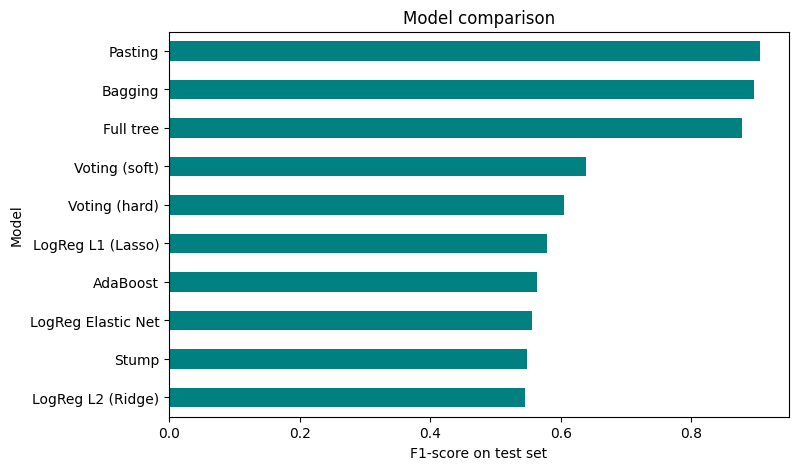

In [82]:
summary["F1"].sort_values().plot(kind="barh", color="teal", figsize=(8, 5))
plt.xlabel("F1-score on test set")
plt.title("Model comparison")
plt.show()